# Swing V2 — o robô é o braço, a pinça são as mãos, a caneta é o taco

Simulação para testar os limites **antes** de ir ao robô. Usa `src/swing_v2.py`
(trajetória e verificações) e `src/run_robot_v2.py` (execução).

| Golfista | Lite 6 | No swing |
|---|---|---|
| tronco inclinado sobre a bola | **J2** | fixa |
| ombro | **J3** | ativa |
| braço | antebraço J3 → J5 (243.6 mm) | |
| pulso (arma e solta) | **J5** | ativa |
| mãos | pinça (TCP a 83.6 mm do flange) | fecha na caneta |
| taco | caneta, `taco` mm para lá dos dedos | |
| rodar a base / antebraço / pinça | J1, J4, J6 | = 0 |

Com J1 = J4 = J6 = 0 os eixos de J2, J3 e J5 são paralelos: o robô é um **braço
plano** no plano vertical x-z — um pêndulo duplo verdadeiro, como o V13 do Lab 1.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML
sys.path.insert(0, os.path.abspath("src"))
%load_ext autoreload
%autoreload 2
import config as C
from kinematics import fk
from swing_v2 import (DEFAULTS, Q_LOAD, swing_v2, check_v2, transition, check_transition,
                      collisions, draw_side, from_joints, FOLGA_COLISAO)
np.set_printoptions(precision=2, suppress=True)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["animation.embed_limit"] = 40

## 1. Prova de que o braço é plano

Eixos de rotação (z de cada referencial) com J1 = J4 = J6 = 0 e J2, J3, J5 quaisquer:

In [2]:
for q in ([0, 0, 0, 0, 0, 0], [0, 43, 100, 0, 58, 0], [0, 20, 150, 0, -40, 0]):
    Ts = fk(q, all_frames=True)
    print(q, "-> eixo J2", Ts[2][:3, 2], "| J3", Ts[3][:3, 2], "| J5", Ts[5][:3, 2],
          "| y de todas as origens", np.round([T[1, 3] for T in Ts], 6).max())

[0, 0, 0, 0, 0, 0] -> eixo J2 [0. 1. 0.] | J3 [-0. -1. -0.] | J5 [ 0.  1. -0.] | y de todas as origens -0.0
[0, 43, 100, 0, 58, 0] -> eixo J2 [0. 1. 0.] | J3 [-0. -1.  0.] | J5 [ 0.  1. -0.] | y de todas as origens -0.0
[0, 20, 150, 0, -40, 0] -> eixo J2 [0. 1. 0.] | J3 [-0. -1. -0.] | J5 [0. 1. 0.] | y de todas as origens -0.0


Os três eixos são sempre ±y e todas as origens têm y = 0: o movimento fica no plano x-z.
Ângulos no plano (a partir da vertical para baixo, + para a frente):
braço $A = 20.9° + q_3 - q_2$, taco $C = q_3 - q_2 - q_5$.

## 2. Perfis das juntas (os do Lab 1)

- **J3 (ombro):** backswing quíntico; downswing com **aceleração constante**,
  $q_3(u) = q_{3,imp} + (q_{3,top}-q_{3,imp})(1-(u/T)^2)$ → velocidade máxima na bola.
- **J5 (pulso):** arma no backswing; no downswing fica armado até $f_{release}T$
  e solta com aceleração constante, chegando à posição de impacto **no mesmo
  instante** que J3.
- **Follow-through:** as duas desaceleram e param juntas.

taco      : 120.0
q2        : 43.0
q3_imp    : 100.0
q5_imp    : 58.0
back      : 47.0
cock      : 45.0
q3_end    : 82.0
f_release : 0.4
t_back    : 2.6
t_down    : 2.1
dt        : 0.01


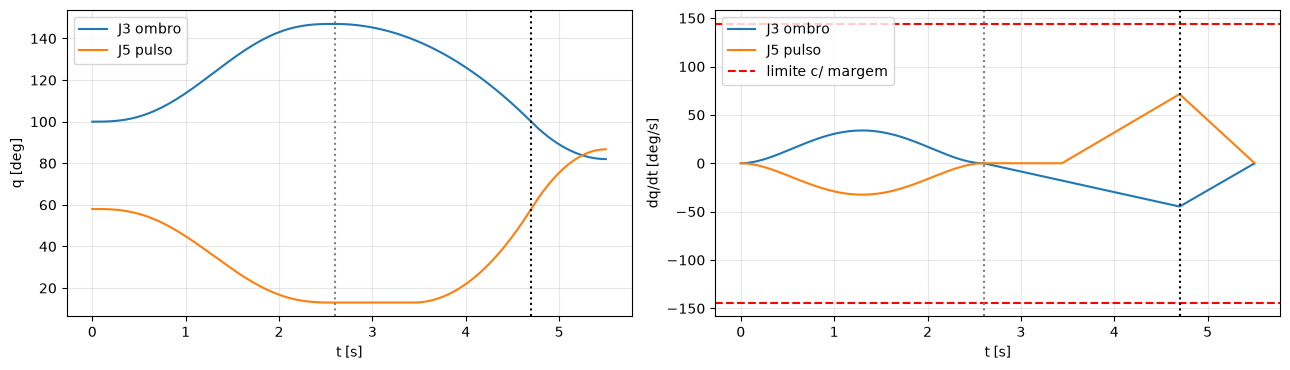

In [3]:
for k, v in DEFAULTS.items():
    print(f"{k:<10}: {v}")
tr = swing_v2()
t, k_imp = tr["t"], tr["k_imp"]
qd = np.gradient(tr["qs"], t, axis=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for j, nome in ((2, "J3 ombro"), (4, "J5 pulso")):
    ax[0].plot(t, tr["qs"][:, j], label=nome)
    ax[1].plot(t, qd[:, j], label=nome)
ax[1].axhline(0.8 * C.JOINT_SPEED_MAX, color="r", ls="--", label="limite c/ margem")
ax[1].axhline(-0.8 * C.JOINT_SPEED_MAX, color="r", ls="--")
for a in ax:
    a.axvline(DEFAULTS["t_back"], color="gray", ls=":"); a.axvline(t[k_imp], color="k", ls=":")
    a.set_xlabel("t [s]"); a.legend(); a.grid(alpha=.3)
ax[0].set_ylabel("q [deg]"); ax[1].set_ylabel("dq/dt [deg/s]")
plt.tight_layout(); plt.show()

## 3. O swing visto de lado (estroboscópio)

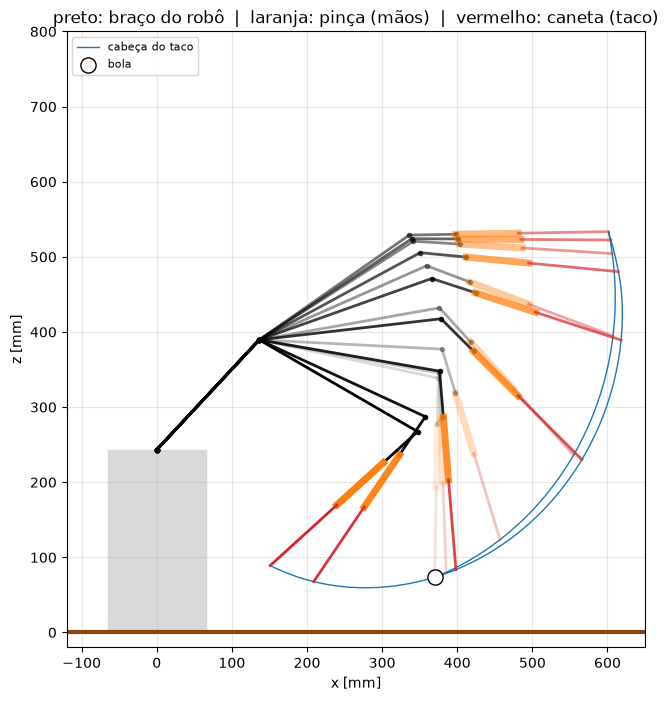

In [4]:
fig, ax = plt.subplots(figsize=(9, 8))
draw_side(ax, tr, frames=np.linspace(0, len(t) - 1, 14).astype(int))
ax.set_xlim(-120, 650); ax.set_ylim(-20, 800)
ax.set_title("preto: braço do robô  |  laranja: pinça (mãos)  |  vermelho: caneta (taco)")
plt.show()

## 4. Animação (tempo real, 10 imagens por segundo)

In [5]:
def animar(tr, fps=10, titulo=""):
    t = tr["t"]
    idx = np.arange(0, len(t), max(int(round(1 / (fps * (t[1] - t[0])))), 1))
    fig, ax = plt.subplots(figsize=(7, 6.5))
    ax.add_patch(plt.Rectangle((-65, 0), 130, 243.3, color="0.85"))
    ax.axhline(0, color="saddlebrown", lw=3)
    ax.plot(*tr["pos"][:, [0, 2]].T, color="tab:blue", lw=0.8, alpha=.5)
    ax.scatter(*tr["bola"][[0, 2]], s=150, color="w", edgecolor="k", zorder=5)
    braco, = ax.plot([], [], "-o", color="k", lw=3, ms=4)
    pinca, = ax.plot([], [], color="tab:orange", lw=7)
    caneta, = ax.plot([], [], color="tab:red", lw=3)
    txt = ax.text(0.02, 0.95, "", transform=ax.transAxes)
    ax.set_xlim(-120, 650); ax.set_ylim(-20, 800); ax.set_aspect("equal"); ax.grid(alpha=.3)
    ax.set_title(titulo)
    def frame(i):
        k = idx[i]
        ch = np.array([tr["J2"][k], tr["J3"][k], tr["J5"][k], tr["pos_flange"][k]])
        braco.set_data(ch[:, 0], ch[:, 2])
        pinca.set_data(*np.array([tr["pos_flange"][k], tr["pos_tcp"][k]])[:, [0, 2]].T)
        caneta.set_data(*np.array([tr["pos_tcp"][k], tr["pos"][k]])[:, [0, 2]].T)
        txt.set_text(f"t = {t[k]:.2f} s")
        return braco, pinca, caneta, txt
    anim = animation.FuncAnimation(fig, frame, frames=len(idx), interval=1000 / fps, blit=True)
    plt.close(fig)
    return HTML(anim.to_jshtml())

animar(tr, titulo="Swing V2 (velocidade planeada)")

## 5. Verificação de viabilidade (o que o enunciado pede)

| Verificação | Critério | Enunciado |
|---|---|---|
| velocidade das juntas | ≤ 0.8 × 180 °/s | (i) |
| velocidade da pinça (efetor final) | ≤ 0.8 × 500 mm/s | (i) |
| alcance | por construção: a trajetória é definida em juntas válidas | (ii) |
| limites das juntas | ≥ 5° de folga | (iii) |
| robô acima da mesa | J3, J5, flange e pinça a ≥ 30 mm | contacto |
| caneta acima da mesa | ponta a ≥ 10 mm | contacto |
| colisões | caneta/pinça vs base e braço, antebraço vs base: ≥ 15 mm entre superfícies | contacto |

A ponta da caneta pode passar dos 500 mm/s: o limite é do efetor final (a pinça) —
é essa a vantagem de ter um taco.

In [6]:
ok, ex = check_v2(tr)
print("\ndeslocações com a caneta presa (junta a junta, 20 deg/s):")
ok &= check_transition(transition(Q_LOAD, tr["qs"][0], DEFAULTS["taco"]), "carregar -> início")
ok &= check_transition(transition(tr["qs"][-1], Q_LOAD, DEFAULTS["taco"]), "fim -> carregar")
print("\n=> swing V2", "VIÁVEL" if ok else "NÃO VIÁVEL")

  vel. juntas        : máx   71.1 deg/s (J5; limite c/ margem 144)  OK
  vel. pinça (TCP)   : máx  379.4 mm/s (limite c/ margem 400)  OK
  golpe (info)       : a cabeça ainda desce  14.0 mm depois do impacto (descendente, como um ferro)
  alcance (info)     : flange a  490.3 mm de J2 — trajetória em juntas, sempre alcançável
  limites juntas     : menor folga  37.3 deg (J5, mínimo 5)  OK
  robô acima da mesa : z mín  167.0 mm (mínimo 30)  OK
  caneta acima mesa  : z mín   59.5 mm (mínimo 10)  OK
  colisões           : menor folga   80.1 mm (caneta-base, mínimo 15)  OK
  cabeça do taco     :    601 mm/s no impacto (máx 602); bola em [370.   -0.   73.5]

deslocações com a caneta presa (junta a junta, 20 deg/s):
  carregar -> início        : robô z mín  193.5, caneta z mín   73.5, folga colisão   92.5 mm  OK
  fim -> carregar           : robô z mín  164.3, caneta z mín   52.0, folga colisão   80.1 mm  OK

=> swing V2 VIÁVEL


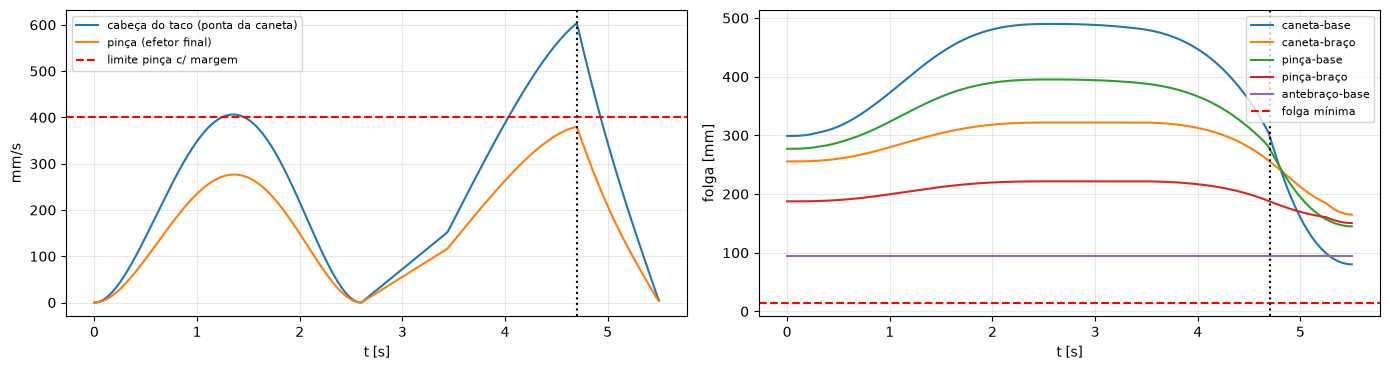

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(t, ex["v_head"], label="cabeça do taco (ponta da caneta)")
ax[0].plot(t, ex["v_flange"], label="pinça (efetor final)")
ax[0].axhline(0.8 * C.TCP_SPEED_MAX, color="r", ls="--", label="limite pinça c/ margem")
ax[0].set_ylabel("mm/s")
for nome, v in ex["col"].items():
    ax[1].plot(t, v, label=nome)
ax[1].axhline(FOLGA_COLISAO, color="r", ls="--", label="folga mínima")
ax[1].set_ylabel("folga [mm]")
for a in ax:
    a.axvline(t[k_imp], color="k", ls=":"); a.set_xlabel("t [s]"); a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Pegar na caneta: pose de carregar e deslocações

O ponto 0 (todas as juntas a 0) tem a pinça virada para baixo a ~7 cm da mesa:
a caneta, a sair para baixo, bateria na mesa. Por isso a caneta é posta numa
**pose de carregar** com a pinça na horizontal, virada para a frente.

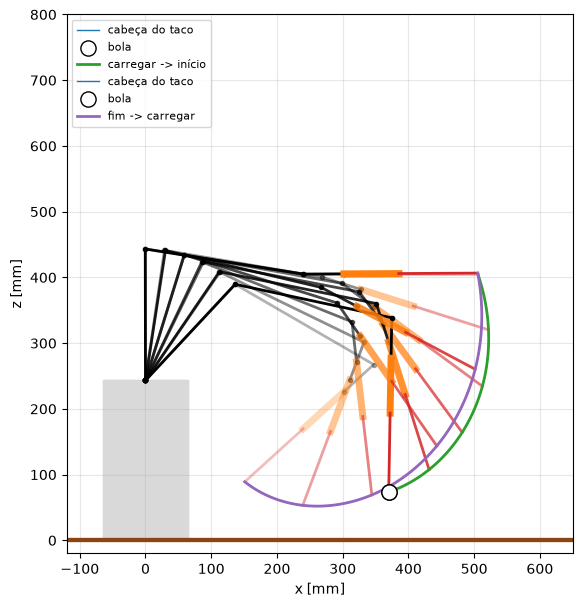

pose de carregar q = [0.0, 0.0, 60.0, 0.0, -30.0, 0.0] | pontas dos dedos em [386.  -0. 405.] mm | ponta da caneta em [506.  -0. 405.]


In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
for qa, qb, cor, nome in ((Q_LOAD, tr["qs"][0], "tab:green", "carregar -> início"),
                          (tr["qs"][-1], Q_LOAD, "tab:purple", "fim -> carregar")):
    trt = transition(qa, qb, DEFAULTS["taco"])
    trt["bola"] = tr["bola"]
    draw_side(ax, trt, frames=np.linspace(0, len(trt["t"]) - 1, 6).astype(int), alpha_min=0.3)
    ax.plot(*trt["pos"][:, [0, 2]].T, color=cor, lw=2, label=nome)
ax.legend(loc="upper left", fontsize=8)
ax.set_xlim(-120, 650); ax.set_ylim(-20, 800)
plt.show()
L = from_joints([0], [Q_LOAD], DEFAULTS["taco"])
print("pose de carregar q =", Q_LOAD, "| pontas dos dedos em", np.round(L["pos_tcp"][0], 0), "mm | ponta da caneta em", np.round(L["pos"][0], 0))

## 7. Testar limites

`testar(**parâmetros)` muda qualquer valor dos `DEFAULTS` e diz se continua viável.
Os varrimentos abaixo mostram o que acontece ao mudar o comprimento da caneta
(que só se mede no lab), a duração do downswing e a inclinação do tronco.

In [9]:
import io, contextlib
def testar(verbose=False, **p):
    trx = swing_v2(dict(p, dt=p.get("dt", 0.02)))
    with contextlib.redirect_stdout(io.StringIO()):
        okx, exx = check_v2(trx)
        okx &= check_transition(transition(Q_LOAD, trx["qs"][0], trx["params"]["taco"]), "")
        okx &= check_transition(transition(trx["qs"][-1], Q_LOAD, trx["params"]["taco"]), "")
    falhas = [k for k, v in exx["res"].items() if not v]
    return okx, exx["v_head"][trx["k_imp"]], exx["v_flange"].max(), trx["bola"], falhas

def varrer(nome, valores, **fixos):
    print(f"{nome:>8} | viável | cabeça [mm/s] | pinça máx [mm/s] | bola [mm]          | falhas")
    for v in valores:
        okx, vh, vf, b, f = testar(**{nome: v}, **fixos)
        print(f"{v:8.1f} | {str(okx):6} | {vh:13.0f} | {vf:16.0f} | {np.round(b, 0)} | {', '.join(f)}")

varrer("taco", [0, 60, 90, 120, 140, 160, 180])

    taco | viável | cabeça [mm/s] | pinça máx [mm/s] | bola [mm]          | falhas
     0.0 | True   |           376 |              379 | [372.  -0. 193.] | 


    60.0 | True   |           485 |              379 | [371.  -0. 134.] | 
    90.0 | True   |           541 |              379 | [371.  -0. 104.] | 
   120.0 | True   |           598 |              379 | [370.  -0.  74.] | 


   140.0 | True   |           636 |              379 | [370.  -0.  54.] | 
   160.0 | True   |           675 |              379 | [369.  -0.  34.] | 
   180.0 | False  |           714 |              379 | [369.  -0.  14.] | caneta acima da mesa


In [10]:
varrer("t_down", [1.6, 1.8, 2.0, 2.1, 2.4, 3.0])

  t_down | viável | cabeça [mm/s] | pinça máx [mm/s] | bola [mm]          | falhas
     1.6 | False  |           782 |              496 | [370.  -0.  74.] | vel. flange
     1.8 | False  |           696 |              442 | [370.  -0.  74.] | vel. flange


     2.0 | True   |           628 |              398 | [370.  -0.  74.] | 
     2.1 | True   |           598 |              379 | [370.  -0.  74.] | 


     2.4 | True   |           524 |              332 | [370.  -0.  74.] | 
     3.0 | True   |           420 |              277 | [370.  -0.  74.] | 


In [11]:
varrer("q2", [30, 35, 40, 43, 46, 50])

      q2 | viável | cabeça [mm/s] | pinça máx [mm/s] | bola [mm]          | falhas


    30.0 | True   |           598 |              379 | [399.  -0. 161.] | 


    35.0 | True   |           598 |              379 | [390.  -0. 127.] | 
    40.0 | True   |           598 |              379 | [378.  -0.  93.] | 


    43.0 | True   |           598 |              379 | [370.  -0.  74.] | 


    46.0 | True   |           598 |              379 | [361.  -0.  54.] | 
    50.0 | True   |           598 |              379 | [347.  -0.  30.] | 


Leitura:
- **caneta**: com caneta muito comprida a ponta aproxima-se da mesa e da base;
  sem caneta (0) é viável mas a cabeça é a ponta dos dedos (mais lenta).
  **Medir a caneta no lab** e correr com `--taco <mm>`.
- **t_down** mais curto que ~2.1 s → a **pinça** passa dos 400 mm/s: é este o
  limite real do swing (as juntas ainda têm folga).
- **q2** (inclinação) muda a altura da bola e a folga à mesa.

## 8. No robô

Pela linha de comandos (a partir de `Lab2/`):

```
python src/run_robot_v2.py                    # ensaio (não mexe)
python src/run_robot_v2.py --go --lento 3     # pega na caneta + swing 3x mais lento
python src/run_robot_v2.py --go --lento 1     # velocidade planeada
python src/run_robot_v2.py --soltar           # abre a pinça na pose de carregar
```

Os dados ficam em `data/run_v2_lento<N>.csv` (q pedido, q medido, pose medida).
A célula seguinte compara o pedido com o medido quando existirem.

In [12]:
import glob
ficheiros = sorted(glob.glob(os.path.join("data", "run_v2_lento*.csv")))
if not ficheiros:
    print("ainda não há data/run_v2_lento*.csv (só depois de correr no robô)")
for f in ficheiros:
    d = np.loadtxt(f, delimiter=",")
    tt, qref, qmed = d[:, 0], d[:, 1:7], d[:, 7:13]
    e = qmed - qref
    print(f"{os.path.basename(f)}: {len(d)} amostras, erro J3 médio {np.abs(e[:,2]).mean():.2f} máx {np.abs(e[:,2]).max():.2f} deg | "
          f"J5 médio {np.abs(e[:,4]).mean():.2f} máx {np.abs(e[:,4]).max():.2f} deg")
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
    for j in (2, 4):
        ax[0].plot(tt, qref[:, j], "--", label=f"J{j+1} pedido"); ax[0].plot(tt, qmed[:, j], label=f"J{j+1} medido")
        ax[1].plot(tt, e[:, j], label=f"J{j+1}")
    ax[0].set_ylabel("q [deg]"); ax[1].set_ylabel("erro [deg]")
    for a in ax: a.set_xlabel("t [s]"); a.legend(fontsize=8); a.grid(alpha=.3)
    ax[0].set_title(os.path.basename(f)); plt.tight_layout(); plt.show()

ainda não há data/run_v2_lento*.csv (só depois de correr no robô)


## 9. V1 vs V2

| | V1 (ontem) | V2 |
|---|---|---|
| quem é o taco | a própria pinça | uma caneta presa na pinça |
| juntas que se mexem | as 6 (J1 73°, J6 124°…) | só J3 e J5 |
| como se envia | poses cartesianas (`set_servo_cartesian`) | ângulos (`set_servo_angle_j`) |
| IK | precisa (do robô) | não precisa |
| limite que manda | ~220 mm/s cartesiano do controlador | 500 mm/s da pinça (fabricante) |
| cabeça do taco no impacto | ~214 mm/s planeado, ≤ 220 medido | ~600 mm/s planeado |
| parecido com o Lab 1 | pouco | pêndulo duplo ombro + pulso |